In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)



TensorFlow version: 2.21.0
NumPy version: 2.5.2


In [4]:
train_path = r"C:\Users\katha\OneDrive\Desktop\DL Project\PlantVillage\train"
val_path = r"C:\Users\katha\OneDrive\Desktop\DL Project\PlantVillage\val"
print("Train path:", train_path)
print("Validation path:", val_path)

Train path: C:\Users\katha\OneDrive\Desktop\DL Project\PlantVillage\train
Validation path: C:\Users\katha\OneDrive\Desktop\DL Project\PlantVillage\val


In [5]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(128, 128),
    batch_size=32,
    shuffle=True
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(128, 128),
    batch_size=32,
    shuffle=False
)

class_names = train_dataset.class_names

print("Total classes:", len(class_names))
print("Classes:", class_names)

Found 43444 files belonging to 38 classes.
Found 10861 files belonging to 38 classes.
Total classes: 38
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato_

In [6]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda images, labels: (
        normalization_layer(images),
        labels
    )
)

val_dataset = val_dataset.map(
    lambda images, labels: (
        normalization_layer(images),
        labels
    )
)

print("Normalization completed!")

Normalization completed!


In [7]:
for images, labels in train_dataset.take(1):
    print("Training Minimum:", images.numpy().min())
    print("Training Maximum:", images.numpy().max())
    print("Training Mean:", images.numpy().mean())

for images, labels in val_dataset.take(1):
    print("Validation Minimum:", images.numpy().min())
    print("Validation Maximum:", images.numpy().max())
    print("Validation Mean:", images.numpy().mean())

Training Minimum: 0.0
Training Maximum: 1.0
Training Mean: 0.44805717
Validation Minimum: 0.0
Validation Maximum: 1.0
Validation Mean: 0.4306768


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(38, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 38)                  │           4,902 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,309,542 (12.62 MB)

 Trainable params: 3,309,542 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [10]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10
)

Epoch 1/10


C:\Users\katha\OneDrive\Desktop\DL Project\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1386s 1s/step - accuracy: 0.4635 - loss: 1.9280 - val_accuracy: 0.7324 - val_loss: 0.9617
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1799s 1s/step - accuracy: 0.6408 - loss: 1.1755 - val_accuracy: 0.7999 - val_loss: 0.6430
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1583s 1s/step - accuracy: 0.6978 - loss: 0.9528 - val_accuracy: 0.8310 - val_loss: 0.5611
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1747s 1s/step - accuracy: 0.7387 - loss: 0.8186 - val_accuracy: 0.8705 - val_loss: 0.4197
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1240s 912ms/step - accuracy: 0.7779 - loss: 0.6900 - val_accuracy: 0.8872 - val_loss: 0.3650
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 2036s 1s/step - accuracy: 0.8100 - loss: 0.5883 - val_accuracy: 0.8933 - val_loss: 0.3411
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 989s 728ms/step - accuracy: 0.8315 - loss: 0.5152 - val_accuracy: 0.9170 - val_loss: 0.2719
Epoch 8/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1101s 810ms/step - accuracy: 0.8512 - lo

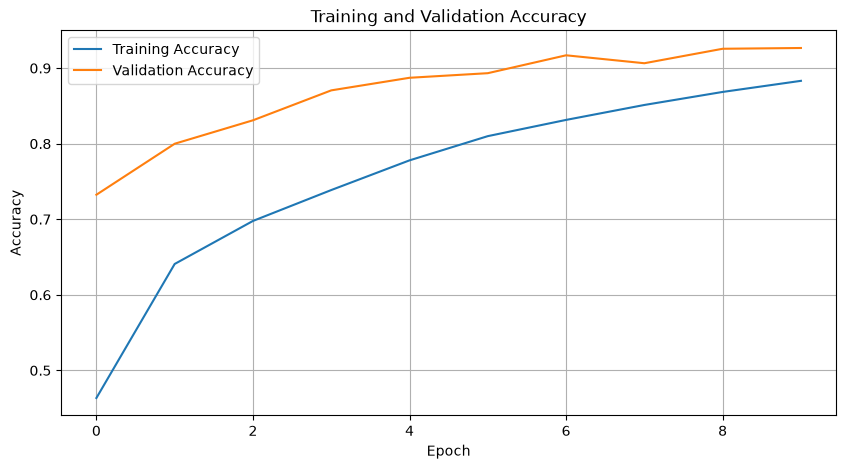

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

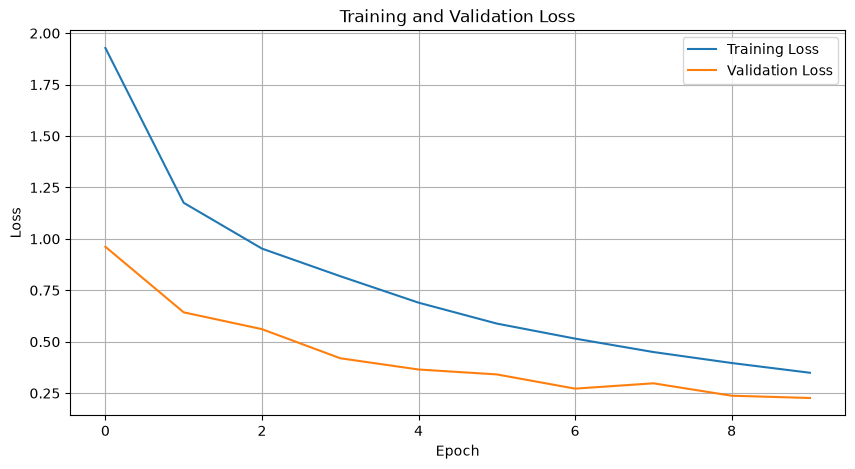

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
loss, accuracy = model.evaluate(val_dataset, verbose=1)

print("Final Validation Loss:", loss)
print("Final Validation Accuracy:", accuracy)
print("Final Validation Accuracy (%):", accuracy * 100)

340/340 ━━━━━━━━━━━━━━━━━━━━ 129s 372ms/step - accuracy: 0.9266 - loss: 0.2265
Final Validation Loss: 0.226473867893219
Final Validation Accuracy: 0.9266181588172913
Final Validation Accuracy (%): 92.66181588172913


In [14]:
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in val_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions completed!")
print("Total samples:", len(y_true))

Predictions completed!
Total samples: 10861


In [15]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.79      0.84      0.81       126
                                 Apple___Black_rot       0.92      0.98      0.95       125
                          Apple___Cedar_apple_rust       0.94      0.82      0.87        55
                                   Apple___healthy       0.85      0.95      0.90       329
                               Blueberry___healthy       0.97      0.98      0.98       300
          Cherry_(including_sour)___Powdery_mildew       0.94      0.97      0.96       210
                 Cherry_(including_sour)___healthy       0.96      0.96      0.96       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.69      0.33      0.45       103
                       Corn_(maize)___Common_rust_       1.00      0.99      0.99       239
               Corn_(maize)___Northern_Leaf_Blight       0.73      0.90      0.

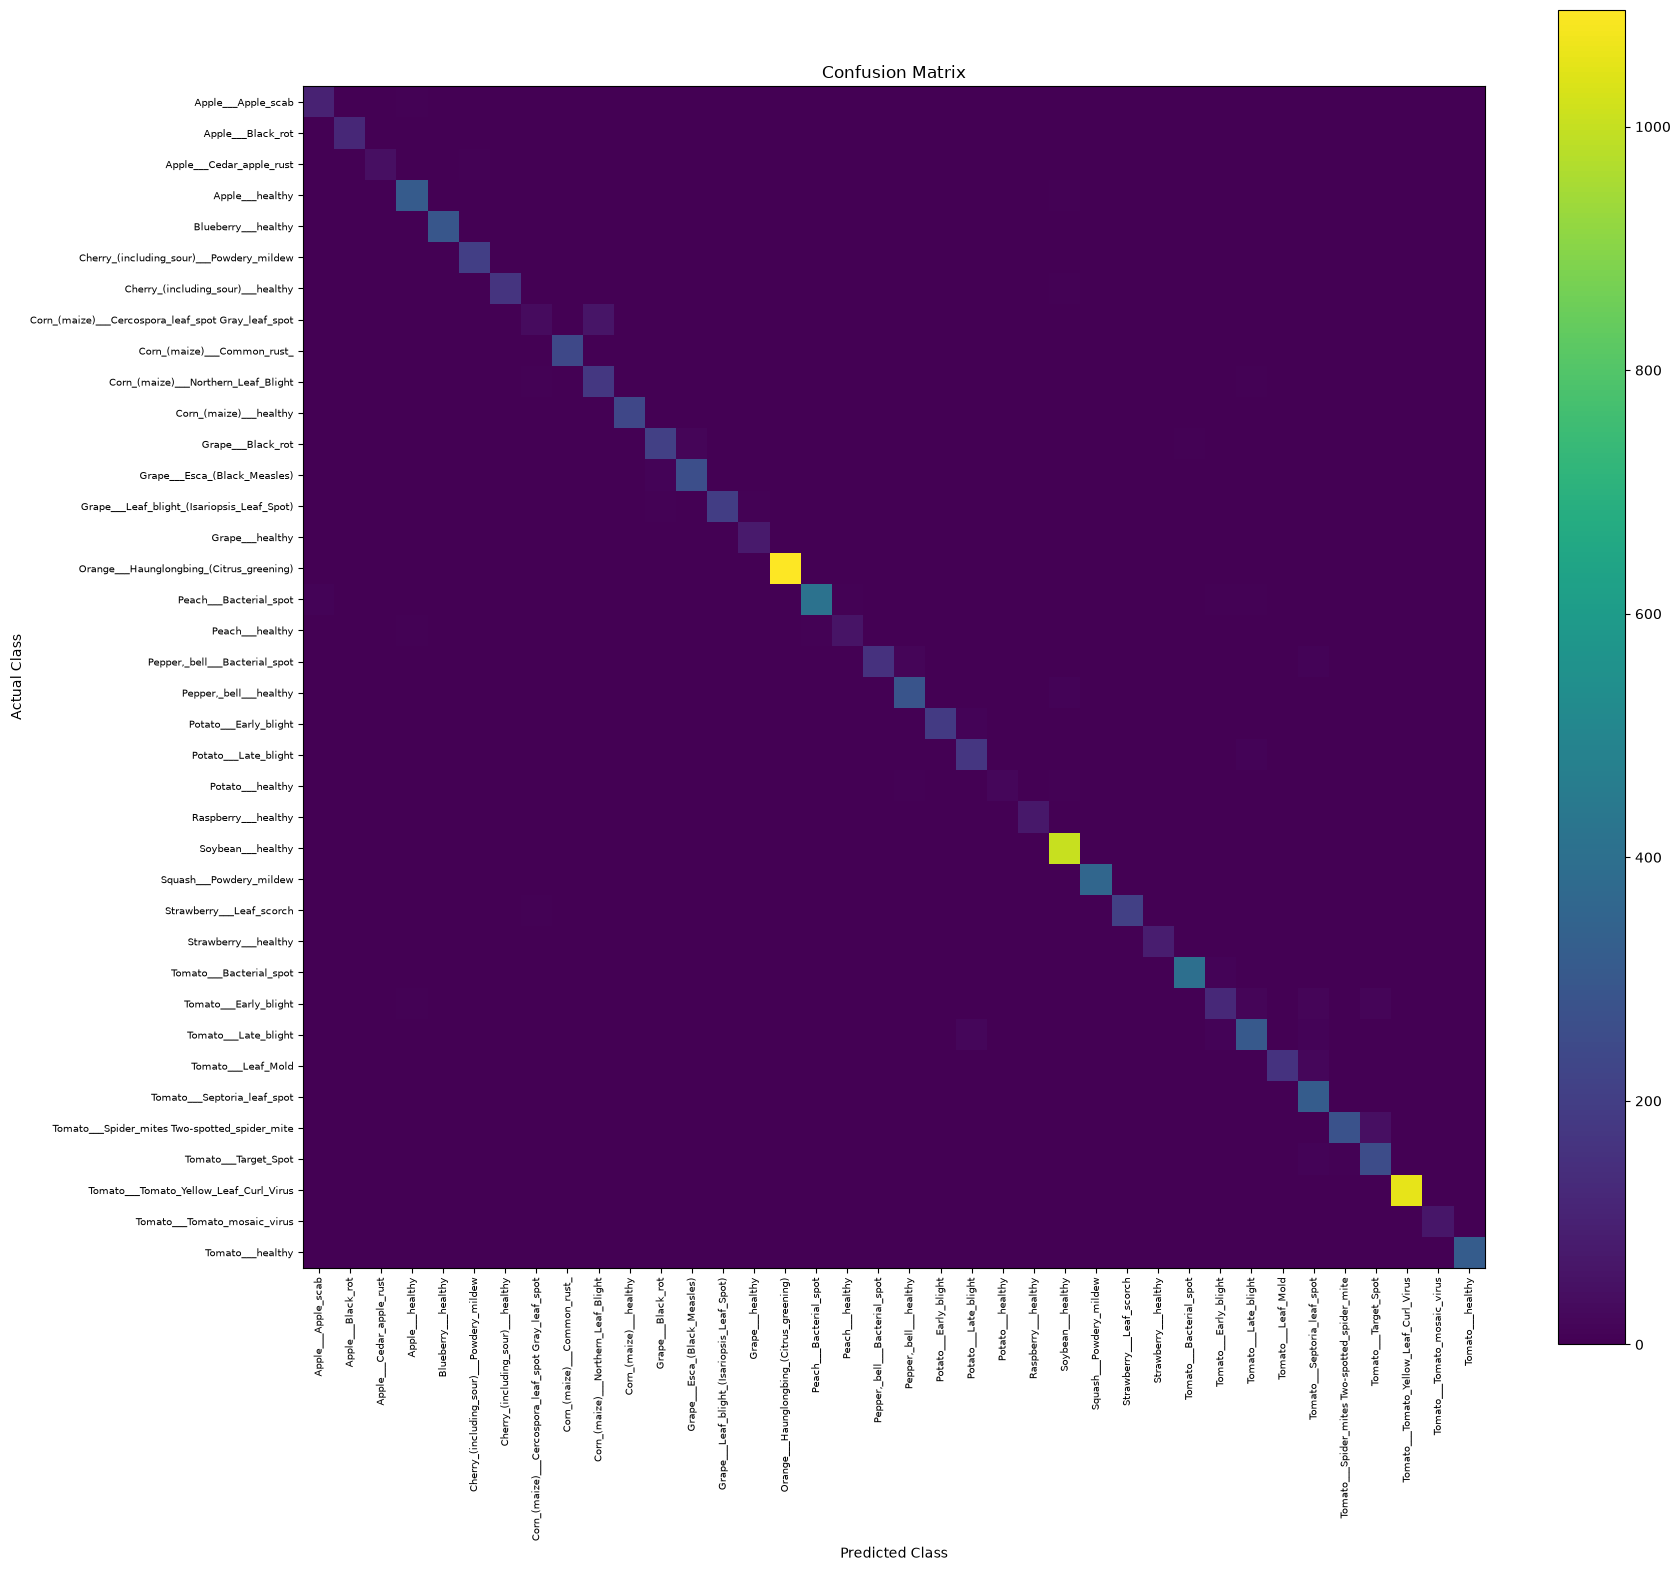

In [16]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 16))

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.colorbar()

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(class_names)),
    class_names,
    fontsize=7
)

plt.tight_layout()
plt.show()

In [17]:
model.save("plant_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [18]:
from PIL import Image

image_path = r"C:\Users\katha\OneDrive\Desktop\DL Project\test_leaf.jpg"

image = Image.open(image_path).convert("RGB")

print("Original image size:", image.size)

image_resized = image.resize((128, 128))

image_array = np.array(image_resized, dtype=np.float32) / 255.0

image_array = np.expand_dims(image_array, axis=0)

print("Input shape:", image_array.shape)

Original image size: (256, 256)
Input shape: (1, 128, 128, 3)


In [19]:
predictions = model.predict(image_array, verbose=0)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]

confidence = predictions[0][predicted_index] * 100

print("Predicted Disease:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

Predicted Disease: Apple___Apple_scab
Confidence: 34.41 %


In [20]:
top_3_indices = np.argsort(predictions[0])[-3:][::-1]

print("Top 3 Predictions:\n")

for index in top_3_indices:
    print(
        class_names[index],
        "->",
        round(predictions[0][index] * 100, 2),
        "%"
    )

Top 3 Predictions:

Apple___Apple_scab -> 34.41 %
Grape___healthy -> 26.0 %
Orange___Haunglongbing_(Citrus_greening) -> 18.68 %


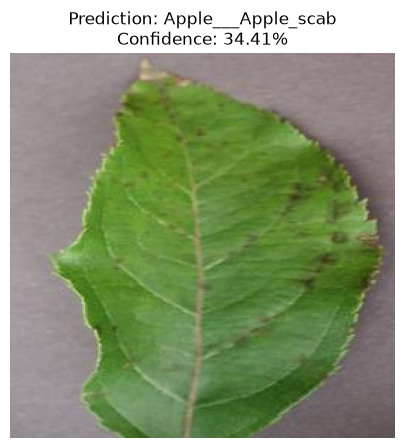

In [21]:
plt.figure(figsize=(5, 5))

plt.imshow(image)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

In [3]:
print(model.output_shape)

NameError: name 'model' is not defined

In [2]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'PlantVillage', 'Plant_Disease_Detection_Final.ipynb', 'plant_disease_model.keras', 'requirements.txt', 'test_leaf.JPG', 'train_model.py', 'venv']


In [4]:
import tensorflow as tf

model = tf.keras.models.load_model("plant_disease_model.keras")

print(model.output_shape)

(None, 38)


In [5]:
print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'PlantVillage', 'Plant_Disease_Detection_Final.ipynb', 'plant_disease_model.keras', 'requirements.txt', 'test_leaf.JPG', 'train_model.py', 'venv']


In [6]:
import os

class_names_38 = sorted([
    folder for folder in os.listdir("PlantVillage")
    if os.path.isdir(os.path.join("PlantVillage", folder))
])

print("Number of classes:", len(class_names_38))
print(class_names_38)

Number of classes: 2
['train', 'val']


In [7]:
import os

train_path = "PlantVillage/train"

class_names_38 = sorted([
    folder
    for folder in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, folder))
])

print("Number of classes:", len(class_names_38))
print(class_names_38)

Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite